## 4. Volatility, liquidity, and the size of deviations

Here we ask whether large premiums and discounts—that is, large deviations between NAV and ETF price—are related to market conditions (volatility and liquidity).

The VIX is used to distinguish low- and high-volatility regimes. The rule applied is:

$$R_{\mathrm{vol},t} = \begin{cases} \text{Low} & \text{if } VIX_t < 15 \\ \text{High} & \text{if } VIX_t \geq 30 \\ \text{Intermediate} & \text{otherwise} \end{cases}$$

For liquidity, quartiles are calculated separately for each ETF:

$$R_{\mathrm{liq},t} = \begin{cases} \text{Low} & \text{if } Volume_t \leq Q_{25} \\ \text{High} & \text{if } Volume_t \geq Q_{75} \\ \text{Intermediate} & \text{otherwise} \end{cases}$$

The cell then compares the mean absolute deviation between low and high regimes without claiming to establish causality.

In [ ]:
from pathlib import Path
import sys
import pandas as pd

RACINE = Path.cwd()
if not (RACINE / "fonctions").is_dir():
    RACINE = RACINE.parent
if str(RACINE) not in sys.path:
    sys.path.insert(0, str(RACINE))

from fonctions.a_donnees import charger_nav, charger_prix, charger_vix
from fonctions.b_analyses import construire_donnees, ajouter_regimes, comparer_regimes, analyser_correction
from fonctions.c_graphiques import tracer_comparaison_regimes, tracer_corrections
import matplotlib.pyplot as plt


,Type,Regime_volatilite,Nb_jours,Prime_moyenne_pct,Ecart_absolu_moyen_pct
0,Actions américaines,Faible,1446,0.0023,0.0202
1,Actions américaines,Forte,158,-0.0186,0.0671
2,Actions émergentes,Faible,1446,0.1876,0.3752
3,Actions émergentes,Forte,158,-0.3442,0.8283
4,Obligations high yield,Faible,1446,0.1880,0.3323
5,Obligations high yield,Forte,158,0.0759,0.5096
6,Obligations investment grade,Faible,1446,0.1214,0.1314
7,Obligations investment grade,Forte,158,-0.1393,0.3412


,Type,Regime_liquidite,Nb_jours,Prime_moyenne_pct,Ecart_absolu_moyen_pct
0,Actions américaines,Faible,901,0.0067,0.0199
1,Actions américaines,Forte,901,-0.0029,0.0332
2,Actions émergentes,Faible,901,0.0668,0.4164
3,Actions émergentes,Forte,901,0.0563,0.5442
4,Obligations high yield,Faible,903,0.1574,0.4625
5,Obligations high yield,Forte,901,0.1088,0.1722
6,Obligations investment grade,Faible,901,0.2398,0.2503
7,Obligations investment grade,Forte,901,0.0304,0.0618


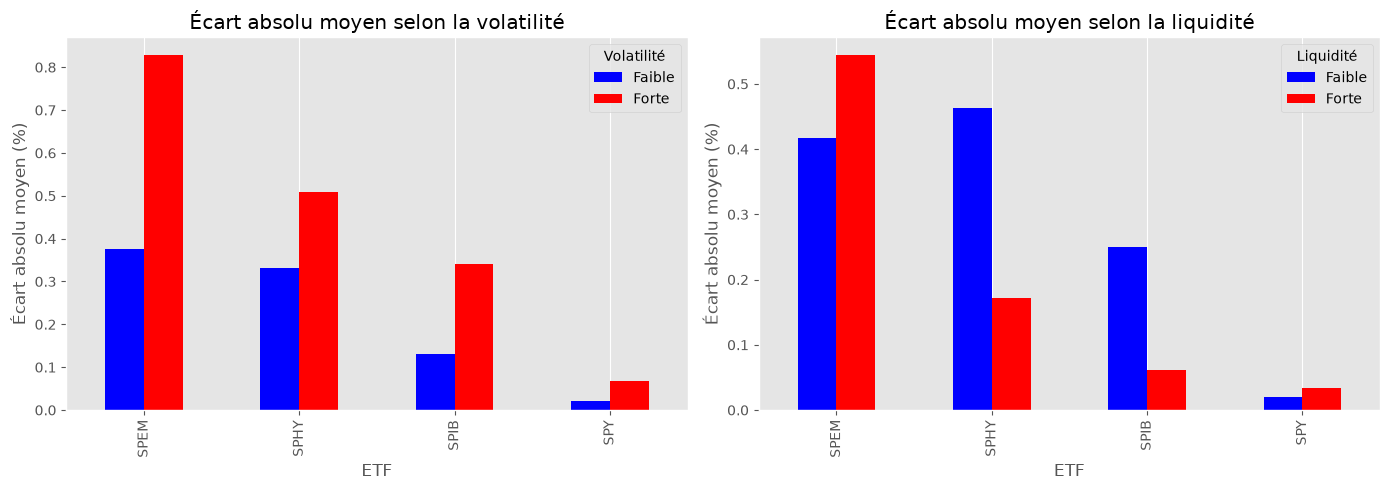

In [2]:
nav = charger_nav()
prix = charger_prix()
donnees = construire_donnees(nav, prix)
date_debut = donnees["Date"].min().strftime("%Y-%m-%d")
date_fin = donnees["Date"].max().strftime("%Y-%m-%d")
vix = charger_vix(date_debut, date_fin)
donnees = ajouter_regimes(donnees, vix)
comparaison_volatilite = comparer_regimes(donnees, "Regime_volatilite")
comparaison_liquidite = comparer_regimes(donnees, "Regime_liquidite")
display(comparaison_volatilite.round(4))
display(comparaison_liquidite.round(4))

fig = tracer_comparaison_regimes(donnees)
display(fig)
plt.close(fig)

### Results of the market-conditions analysis

Under high volatility, the mean absolute deviation increases for all four categories: **0.0202% → 0.0671%** for U.S. equities, **0.3752% → 0.8283%** for emerging-market equities, **0.1314% → 0.3412%** for investment-grade bonds, and **0.3323% → 0.5096%** for high-yield bonds. The effect is particularly pronounced for SPEM.

The volume effect is heterogeneous: the deviation increases when volume is high for U.S. and emerging-market equities, but decreases for bonds (**0.4625% → 0.1722%** for high yield; **0.2503% → 0.0618%** for investment grade). Volume is therefore an imperfect proxy for liquidity.

## 5. Correction on the following day

We ask whether deviations revert on the following day, when market participants arbitrage the difference between NAV and ETF values.

We retain absolute deviations of at least 0.25%, then compare their value with that of the following session. The change in deviation is defined as:

$$\Delta_t = \mathrm{Absolute\ deviation}_{t+1} - \mathrm{Absolute\ deviation}_t$$

A correction is counted when:

$$\mathrm{Correction}_t = \mathbb{1}(\Delta_t < 0)$$

The correction rate is then:

$$\mathrm{Correction\ rate} = \frac{\text{number of corrections}}{\text{number of large deviations observed}} \times 100$$

In the scatter plot, observations below the diagonal correspond to a correction, while those above it correspond to a worsening of the deviation recorded on the previous day.

,ETF,Classe,Type,Nb_dates,Taux_correction_pct,Variation_abs_moyenne_1j
0,SPEM,Actions,Actions émergentes,2292,68.6736,-0.1663
1,SPHY,Obligations,Obligations high yield,1635,67.2783,-0.1050
2,SPIB,Obligations,Obligations investment grade,552,65.2174,-0.0526
3,SPY,Actions,Actions américaines,11,100.0000,-0.3203


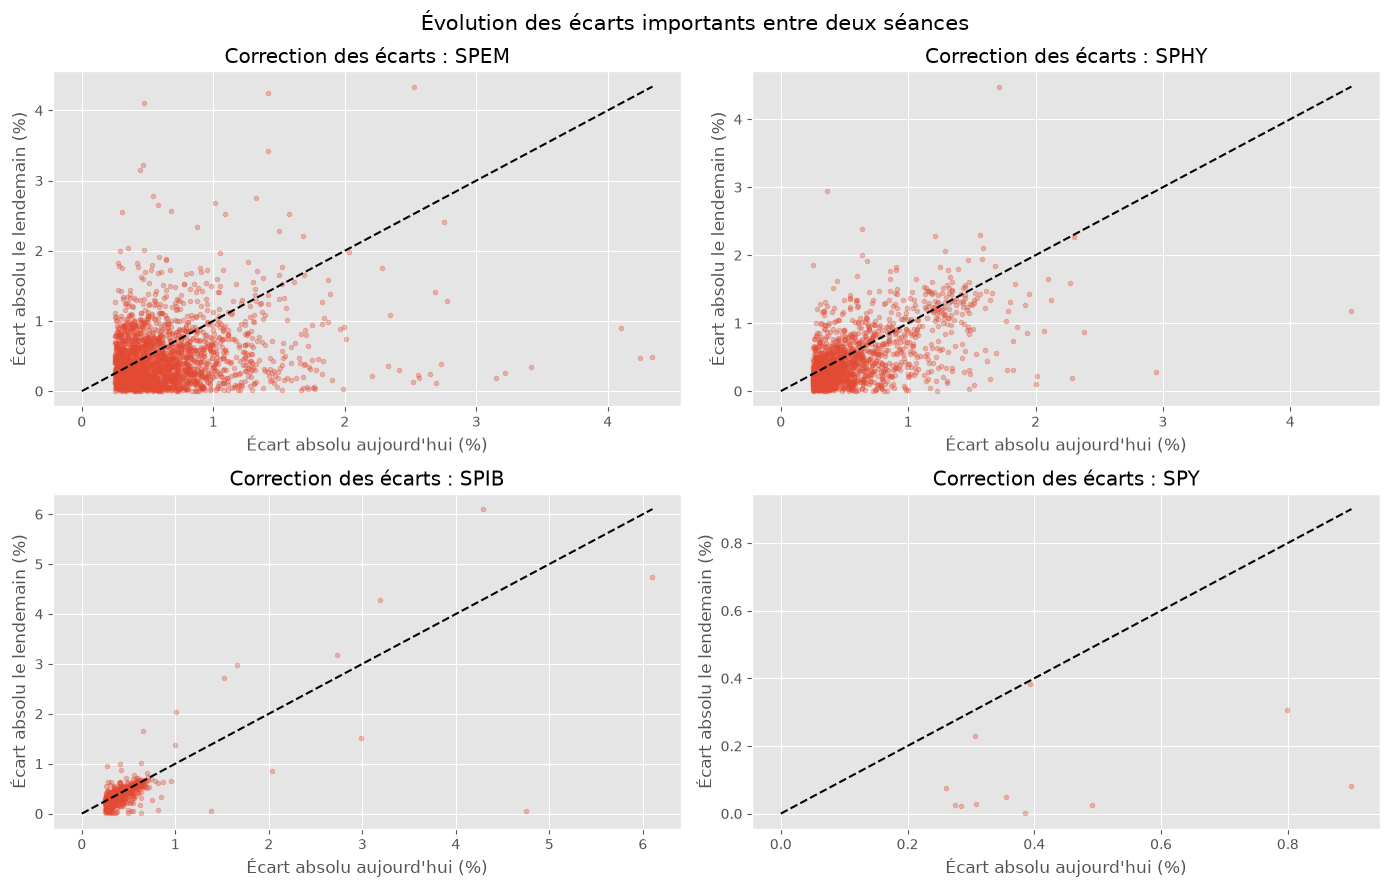

In [3]:
donnees_ecarts_importants, vitesse_correction = analyser_correction(donnees)
display(vitesse_correction.round(4))

fig = tracer_corrections(donnees_ecarts_importants)
display(fig)
plt.close(fig)

### Results of the correction analysis

The correction rate for large deviations is **68.67% for SPEM** (mean change: −0.1663 percentage points), **67.28% for SPHY** (−0.1050), **65.22% for SPIB** (−0.0526), and **100% for SPY** (−0.3203).

In most cases, arbitrage therefore appears to reduce the deviations.

The SPY result should be interpreted cautiously because it is based on only **11 dates**. Overall, large deviations tend to decrease during the following session, without disappearing systematically.

# Conclusion and limitations

## Conclusion

The ETF and the underlying portfolio can provide the same exposure while having different prices because the ETF price is determined continuously by supply and demand, whereas the NAV is calculated from the valuation of the portfolio's assets, often at a different time and using different conventions. The results show that deviations are small for SPY, larger for SPEM and SPHY, generally widen when volatility is high, and often correct during the following session.

## Project limitations

- The NAV and closing price may correspond to different points in time during the same day.
- The VIX is a volatility indicator for the S&P 500, not a measure specific to each ETF.
- The thresholds `0.25%`, `0.5%`, `1%`, `VIX < 15`, and `VIX ≥ 30` are analytical choices; they are not universal thresholds.
- Volume is an imperfect proxy for liquidity.
- The project describes trends, not causality.